In [16]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import GradientBoostingRegressor
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

# 1. Сгенерируйте данные о сотрудниках, включающие количество отработанных часов в неделю,
#  профессиональный опыт, возраст, уровень образования и показатель производительности.
# Сгенерирован, сохранён в эксель

employee_data = pd.read_excel(r'W:\Python_job\ISUCT\2026\BigData\df.xlsx')



# Проведите предварительную проверку данных, оцените их структуру, корректность и наличие пропущенных значений.
employee_data.describe()

# Пропусков нет, 1000/1000 строк во всех столбцах


,Experience,Skills,Motivation,TrainingHours,TasksCompleted,Performance
count,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000
mean,9.633000,5.516946,5.535820,50.776000,55.325000,87.387786
std,6.220531,2.556893,2.633315,28.677486,26.014999,16.729901
min,0.000000,1.002138,1.001696,0.000000,10.000000,39.761338
25%,4.000000,3.283129,3.173610,26.000000,32.000000,75.888332
50%,9.500000,5.636570,5.722295,52.500000,56.000000,87.323630
75%,15.000000,7.724122,7.780566,75.000000,77.000000,99.059261
max,20.000000,9.994181,9.997424,100.000000,100.000000,136.978620


In [17]:
# Постройте модель линейной регрессии для прогнозирования производительности сотрудников.

X = employee_data.drop(columns=['Performance'])
y = employee_data['Performance']

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

model = LinearRegression()
model.fit(X_train, y_train)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](5,)","[1.18,4.03,2.59,0.12,0.25]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Defined only when `X`has feature names that are all strings... versionadded:: 1.0","ndarray[object](5,)","['Experience','Skills','Motivation','TrainingHours','TasksCompleted']"
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.",float64,19.25
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,5
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int64,np.int64(5)


In [18]:
# Оцените качество модели с использованием подходящих метрик и проанализируйте ошибки прогнозирования.

y_pred = model.predict(X_test)

mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred)

print("========== РЕЗУЛЬТАТЫ МОДЕЛИ ==========")
print(f"MSE:  {mse}")
print(f"RMSE: {rmse}")
print(f"R2:   {r2}")


========== РЕЗУЛЬТАТЫ МОДЕЛИ ==========
MSE:  17.386352815271934
RMSE: 4.169694570981421
R2:   0.9397564593741605


In [19]:
# Обучаем модель град. бустинга
boosting_model = GradientBoostingRegressor(
    n_estimators=200,
    learning_rate=0.05,
    max_depth=3,
    random_state=42
)
boosting_model.fit(X_train, y_train)
y_pred_boosting = boosting_model.predict(X_test)

In [20]:
def evaluate_model(name, y_true, y_pred_vals):
    return {
        'Модель': name,
        'MAE': mean_absolute_error(y_true, y_pred_vals),
        'RMSE': np.sqrt(mean_squared_error(y_true, y_pred_vals)),
        'R2': r2_score(y_true, y_pred_vals)
    }

# Сравниваем показатели двух моделей

results = pd.DataFrame([
    evaluate_model('Линейная регрессия', y_test, y_pred),
    evaluate_model('Градиентный бустинг', y_test, y_pred_boosting)
])

results

,Модель,MAE,RMSE,R2
0,Линейная регрессия,3.321585,4.169695,0.939756
1,Градиентный бустинг,3.974257,4.950955,0.915066


In [21]:
coef_df = pd.DataFrame({
    'Признак': X.columns,
    'Коэффициент': model.coef_
})

coef_df['Абсолютный коэффициент'] = coef_df['Коэффициент'].abs()
coef_df = coef_df.sort_values('Абсолютный коэффициент', ascending=False)

print("\nКоэффициенты линейной регрессии:")
print(coef_df.to_string(index=False))


Коэффициенты линейной регрессии:
       Признак  Коэффициент  Абсолютный коэффициент
        Skills     4.031413                4.031413
    Motivation     2.592514                2.592514
    Experience     1.181154                1.181154
TasksCompleted     0.252157                0.252157
 TrainingHours     0.124236                0.124236


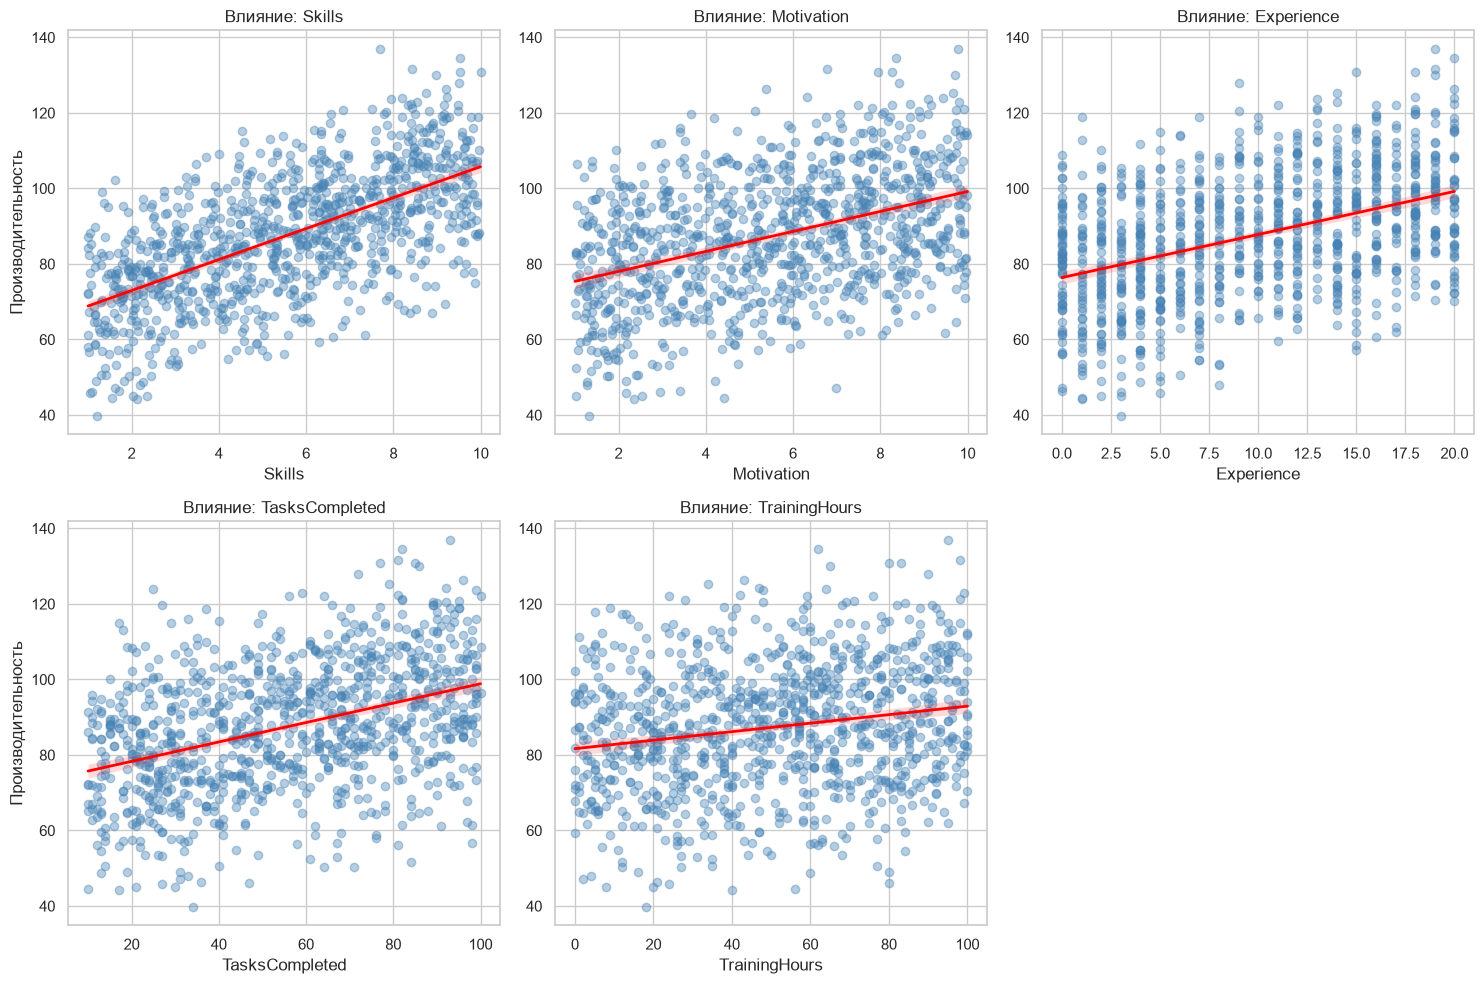

In [ ]:

sns.set_theme(style="whitegrid")

fig, axes = plt.subplots(2, 3, figsize=(15, 10))
axes = axes.flatten()

# Список признаков из таблицы
features = ['Skills', 'Motivation', 'Experience', 'TasksCompleted', 'TrainingHours']

for i, feature in enumerate(features):
    sns.regplot(
        data=employee_data,
        x=feature,
        y='Performance',
        ax=axes[i],
        scatter_kws={'alpha': 0.4, 'color': 'steelblue'},
        line_kws={'color': 'red', 'linewidth': 2}
    )
    axes[i].set_title(f'Влияние: {feature}')
    axes[i].set_xlabel(feature)
    axes[i].set_ylabel('Производительность' if i % 3 == 0 else '')

fig.delaxes(axes[5])

plt.tight_layout()
plt.show()

Основные метрики производительности: Навыки, мотивация. Развитие этих навыков даёт больший прирост производительности
Опыт и кол-во выполненных задач взаимосвязаны, это не те навыки, которые можно "развить"
Кол-во часов обучения не влияет на результаты производительности. Возможно влияет фактор вовлечённости сотрудников в обучение.

____________________________
Модель линейной регрессии подходит больше, так как при одинаковых вводных она показала лучшие результаты.

| Модель | MAE | RMSE | R2 |
| :--- | :--- | :--- | :--- |
| **Линейная регрессия** | 3.321585 | 4.169695 | 0.939756 |
| **Градиентный бустинг** | 3.974257 | 4.950955 | 0.915066 |



**Но всё это работает только на синтетическом датасете с заренее известными линейными зависимостями (df составлен таким образом, чтобы зависимость была)**


________________________________
* **MAE (Mean Absolute Error — Средняя абсолютная ошибка):** 
Показывает среднее по модулю отклонение предсказанных значений от фактических. Например, MAE = 3.32 означает, что модель ошибается в среднем на 3.32 балла.
* **RMSE (Root Mean Squared Error — Корень из среднеквадратичной ошибки):** 
Также измеряется в единицах целевой переменной, но перед усреднением каждая ошибка возводится в квадрат. Если RMSE заметно больше MAE, это сигнализирует о наличии редких, но больших ошибок прогноза. В нашей линейной регрессии разница между ними невелика (4.17 против 3.32), что говорит о стабильности прогнозов.

* **$R^2$ (Коэффициент детерминации):** 
Показывает долю дисперсии (изменчивости) целевой переменной, которую смогла объяснить модель на основе имеющихся признаков. Принимает значения от 0 до 1. Значение $R^2 = 0.94$ означает, что выбранные факторы (навыки, мотивация, опыт и т.д.) объясняют 94% всей разницы в производительности между сотрудниками, а оставшиеся 6% приходятся на случайный шум или неучтенные в датасете характеристики.